In [ ]:
import numpy as np
import pandas as pd
from google.colab import files

In [ ]:
DES_Data = pd.read_csv("/content/DES-Dovekie_HD (1).csv", skiprows=8, delim_whitespace=True)
DES_Data

/tmp/ipykernel_11555/896039407.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  DES_Data = pd.read_csv("/content/DES-Dovekie_HD (1).csv", skiprows=8, delim_whitespace=True)


,VARNAMES:,CID,IDSURVEY,zHD,zHEL,MU,MUERR,MUERR_VPEC,MUERR_SYS,PROBIA_BEAMS
0,SN:,Gaia16agf,150,0.02509,0.02507,35.25995,0.1773,0.0731,0.05631,1.00000
1,SN:,2003it,63,0.02510,0.02528,35.08017,0.1641,0.0730,0.04157,1.00000
2,SN:,2007cq,64,0.02510,0.02604,34.98002,0.1331,0.0730,0.03455,1.00000
3,SN:,AT2017cfc,150,0.02512,0.02403,35.13565,0.1211,0.0730,0.03976,1.00000
4,SN:,2007sw,65,0.02517,0.02428,35.21658,0.1559,0.0728,0.04029,1.00000
...,...,...,...,...,...,...,...,...,...,...
1815,SN:,1263785,10,1.06420,1.06498,44.23028,0.1451,0.0028,0.03884,0.99765
1816,SN:,1842087,10,1.08349,1.08430,44.52159,0.1518,0.0027,0.13563,0.99789
1817,SN:,1339609,10,1.12132,1.12212,44.20175,0.1075,0.0026,0.06526,0.98858
1818,SN:,1446080,10,1.13057,1.13140,44.52710,0.1585,0.0026,0.11217,0.99945


In [ ]:
DES_dat = pd.read_csv('/content/DES-Dovekie_HD (1).csv', usecols=[3,4,5,6],skiprows=8, delim_whitespace=True)

/tmp/ipykernel_11555/1888060294.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  DES_dat = pd.read_csv('/content/DES-Dovekie_HD (1).csv', usecols=[3,4,5,6],skiprows=8, delim_whitespace=True)


In [ ]:
DES_dat

,zHD,zHEL,MU,MUERR
0,0.02509,0.02507,35.25995,0.1773
1,0.02510,0.02528,35.08017,0.1641
2,0.02510,0.02604,34.98002,0.1331
3,0.02512,0.02403,35.13565,0.1211
4,0.02517,0.02428,35.21658,0.1559
...,...,...,...,...
1815,1.06420,1.06498,44.23028,0.1451
1816,1.08349,1.08430,44.52159,0.1518
1817,1.12132,1.12212,44.20175,0.1075
1818,1.13057,1.13140,44.52710,0.1585


In [ ]:
DES_dat.to_csv('DES_file.txt', sep='\t', index=False)
files.download('DES_file.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
mask = DES_Data['zHD'] >0.00

In [ ]:
Redshift = DES_Data['zHD']

Redshift_1 = DES_Data['zHEL']
dist_mod =  DES_Data['MU']
dist_mod_err = DES_Data['MUERR']
Redshift_cmb = DES_Data['zHD'][mask]

In [ ]:
Redshift_cmb

,zHD
0,0.02509
1,0.02510
2,0.02510
3,0.02512
4,0.02517
...,...
1815,1.06420
1816,1.08349
1817,1.12132
1818,1.13057


In [ ]:
data_sn = np.load('/content/STAT+SYS.npz')
print(data_sn.files)

['nsn', 'cov', 'allow_pickle']


In [ ]:
import numpy as np

# 1. Load the binary compressed NPZ file
data = np.load("/content/STAT+SYS.npz")

# 2. View all internal array keys to find your data name
print("Available arrays:", data.files)

# 3. Extract the array and save it directly to a text file
# Replace 'arr_0' with your actual array key name
np.savetxt("DES_COV.txt", data['cov'],delimiter=",")


Available arrays: ['nsn', 'cov', 'allow_pickle']


In [ ]:
n = data_sn['nsn']
n

array([1820])

In [ ]:
n = len(Redshift)
inv_cov = np.zeros((n, n))
inv_cov[np.triu_indices(n)] = data_sn['cov']
i_lower = np.tril_indices(n, -1)
inv_cov[i_lower] = inv_cov.T[i_lower]
C = np.linalg.inv(inv_cov)

In [ ]:
def wd(z,params):   # define equation of state
  w = params[1]
  return w

In [ ]:
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

c = 2.99792458e5  # km/s
H0 = 70         #Km/s/Mpc

def E(z, om0, w):
    return np.sqrt(om0 * (1+z)**3 + (1 - om0) * (1+z)**(3*(1+w)))

def equation(z, y, params):   # define equation to solve luminosity distance
    D_L = y[0]   # this indicates that I am using only one variable, which is luminosity distance here.
    om0,w = params
    H = H0 * E(z, om0, w)
    dDL_dz = (D_L / (1+z)) + ((1+z) * (c / H ) )# differential equation of luminosity distance
    return [dDL_dz]

def ode_solution(params):   # solving the solution for differential equation
    om0, w = params
    # Integrate D_L
    z_eval = np.linspace(0, 3, 1000)  # set the values of redshifts with 1000 points
    sol = solve_ivp(lambda z, y: equation(z, y, params),
                    [0, 3], [0.0],
                    t_eval=z_eval, rtol=1e-6, atol=1e-9)

    D_L = sol.y[0] # value of lumninosity in array for each z_sol
    z_sol = sol.t
    dl_val = interp1d(z_sol, D_L, kind='linear', fill_value="extrapolate") # used interpolation because sol.t gives me discrete value in range from [0,3] in steps of 1000. Actual redshfits may not coincide hence interpolation helps to return smooth function.


    def chi_sn(dl_val, redshift):   # defining chi-square for Sne


        res_sn = np.zeros(len(redshift))

        mu_values_sn = 5 * np.log10((1+Redshift_1) * dl_val(redshift)/(1+redshift)) + 25



        res_sn = dist_mod - mu_values_sn
        res_sum = (res_sn.T @ inv_cov @ res_sn)
        B = np.sum(res_sn @ inv_cov)
        C = np.sum(inv_cov)
        chi2 = res_sum - (B**2 / C) + np.log(C / (2 * np.pi))
        return -0.5*chi2


    CHI_SN = chi_sn(dl_val = dl_val, redshift=Redshift)

    return CHI_SN

In [ ]:
ode_solution([0.264,-0.8])

np.float64(-820.2134930388369)

In [ ]:
def log_prob(params):


    res = ode_solution(params)

    if np.any(np.isinf(res)) or np.any(np.isnan(res)):

        return -np.inf



    return  res

In [ ]:
def liklihood(params):

  om0 = params[0]
  #H0 = params[1]
  #rd = params[2]
  w  = params[1]

  if not 0 < om0 < 0.7:
    return -np.inf
  #if not 30 < H0 < 100:
    #return -np.inf
  #if not 100 < rd < 150:
    #return -np.inf
  if not -2 < w < 0:
    return -np.inf

  res = log_prob(params)

  return res

In [ ]:
from scipy.special import expi
!pip install emcee
! pip install getdist
from scipy.integrate import solve_ivp
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import getdist
from getdist import plots, MCSamples

import arviz as az

import emcee
from datetime import datetime

In [ ]:
nwalker = 24
ndim = 2
niter = 2000

p0 = np.random.uniform(low=[0.0,-2.0], high=[0.7,0.0], size=(nwalker,ndim))

with Pool(processes=10) as pool:
  sampler = emcee.EnsembleSampler(nwalker, ndim, liklihood, pool=pool, live_dangerously=None)
  sampler.run_mcmc(p0, niter, progress = True)

dis = 400
thi = 5

chains = sampler.get_chain(flat=True, discard=dis, thin = thi)
samples_save = pd.DataFrame(chains)
samples_save.to_csv( f'/content/sample_data.csv')
name = ['Omega_m','w']
labels1 = [r'\Omega_{m}',r'w']
sample2 = MCSamples(samples=chains,names=name, labels=labels1)

#print(f"Here is the result for {file_name} on:")

az_data = az.from_emcee(sampler, var_names=name)
r_hat = az.rhat(az_data)
print("Gelman-Rubin statistic (R_hat):", r_hat)

100%|██████████| 2000/2000 [16:12<00:00,  2.06it/s]


Removed no burn in
Gelman-Rubin statistic (R_hat): <xarray.Dataset> Size: 16B
Dimensions:  ()
Data variables:
    Omega_m  float64 8B 1.025
    w        float64 8B 1.024
Attributes:
    created_at:                 2026-06-02T09:43:52.499783+00:00
    arviz_version:              0.22.0
    inference_library:          emcee
    inference_library_version:  3.1.6


In [ ]:
import pandas as pd
samples = pd.read_csv(f"/content/sample_data.csv")
col=['omega_m','H0','rd','w']
preds = pd.DataFrame(samples)
preds = preds.drop(preds.columns[0], axis=1)

preds

,0,1
0,0.125859,-0.632703
1,0.277826,-0.876153
2,0.380237,-1.108595
3,0.237209,-0.754558
4,0.180445,-0.714249
...,...,...
7675,0.102562,-0.627377
7676,0.176439,-0.711580
7677,0.004690,-0.542456
7678,0.289384,-0.858153


In [ ]:
N_sn = len(Redshift)
N_sn

1820

Maximum log liklihood is  -819.5152406404831
Min chi_square:  1639.0304812809661
Reduced chi_squre is:  0.901556920396571
Parameters at Maximum Likelihood: [0.12585927 0.2778258  0.38023668 ... 0.00469046 0.28938393 0.24737527]



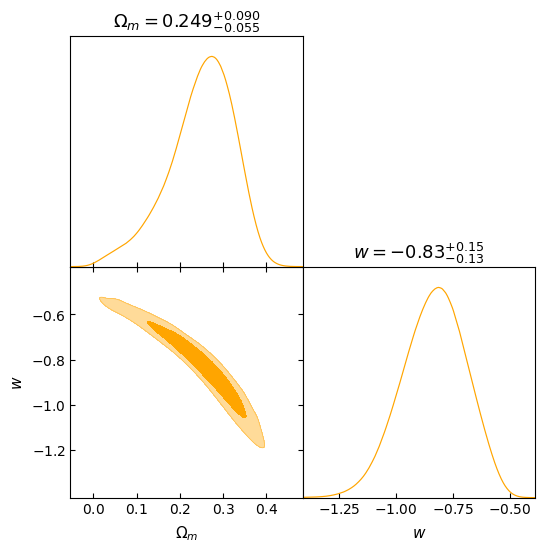

In [ ]:
log_likelihoods = sampler.get_log_prob()

log_likelihood = np.max(log_likelihoods)

print("Maximum log liklihood is ", log_likelihood)

max_likelihood_index = np.argmax(log_likelihood)
max_likelihood_params = sample2[max_likelihood_index]

chi2val = -2* log_likelihood
print("Min chi_square: ", chi2val)

reduced = chi2val/(N_sn-ndim)

print("Reduced chi_squre is: ", reduced)

print(f"Parameters at Maximum Likelihood: {max_likelihood_params}\n")




#aic_value = aic(log_likelihood,ndim)
#bic_value=bic(log_likelihood,ndim,N)


#print("AIC values:", aic(log_likelihood,ndim))

#print("BIC Values: ", bic_value)




g = plots.get_subplot_plotter(width_inch=6)  # Adjust width of the plot in

g.settings.figure_legend_frame = True  # Remove frame around the legend
g.settings.alpha_filled_add = 0.6  # Adjust transparency of filled contours
g.settings.title_limit_fontsize = 14  # Limit title fontsize to 14
g.settings.axes_labelsize = 12  # Adjust label fontsize
g.settings.legend_fontsize = 10  # Adjust legend fontsize
g.settings.colorbar_axes_fontsize = 10  # Adjust colorbar fontsize
g.triangle_plot(sample2, name, filled=True, legend_loc='upper right', contour_colors=['orange'],title_limit=1)

#g.export(f'figure/{file_name}.pdf')